In [54]:
from pathlib import Path
import sys
from pathlib import Path

project_root = Path.cwd().parent
sys.path.insert(0, str(project_root))

print("current directory:", Path.cwd())
print("Parent directory:", Path.cwd().parent)

current directory: c:\users\el khaldouni\deepfake-project\notebooks
Parent directory: c:\users\el khaldouni\deepfake-project


In [55]:
print((Path.cwd() / "data").is_dir())
print((Path.cwd().parent / "data").is_dir())

False
True


In [56]:
from src.preprocessing import load_image , center_crop
import matplotlib.pyplot as plt

real_image properties: (512, 512, 3) uint8 93 237
fake_image properties: (512, 512, 3) uint8 0 253


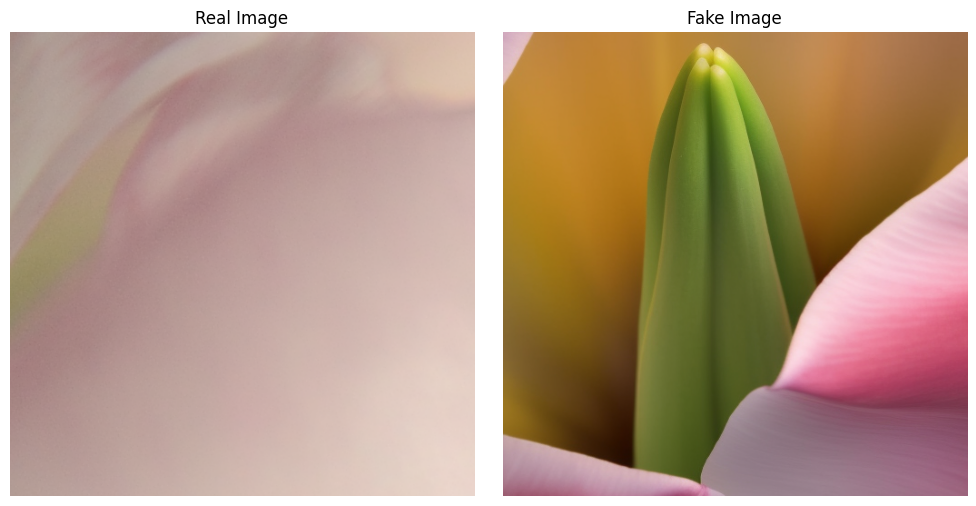

In [57]:
real_path="../data/real/r1b4e82c4t.png"
Fake_path="../data/fake/r1b4e82c4t.png"

real_image=load_image(real_path)
fake_image=load_image(Fake_path)

real_image=center_crop(real_image, 512)
fake_image=center_crop(fake_image, 512)
print("real_image properties:", real_image.shape, real_image.dtype, real_image.min(), real_image.max())
print("fake_image properties:", fake_image.shape, fake_image.dtype, fake_image.min(), fake_image.max())

fig, axes = plt.subplots(1, 2, figsize=(10, 5))

axes[0].imshow(real_image)
axes[0].set_title("Real Image")
axes[0].axis("off")

axes[1].imshow(fake_image)
axes[1].set_title("Fake Image")
axes[1].axis("off")

plt.tight_layout()
plt.show()


## Spectral Analysis  :

real_fft properties: (512, 512) complex64 (-456423.72-609557.7j) (4.4942652e+07+0j)
fake_fft properties: (512, 512) complex64 (-2.7925328e+06-1.47468e+06j) (3.201003e+07+0j)


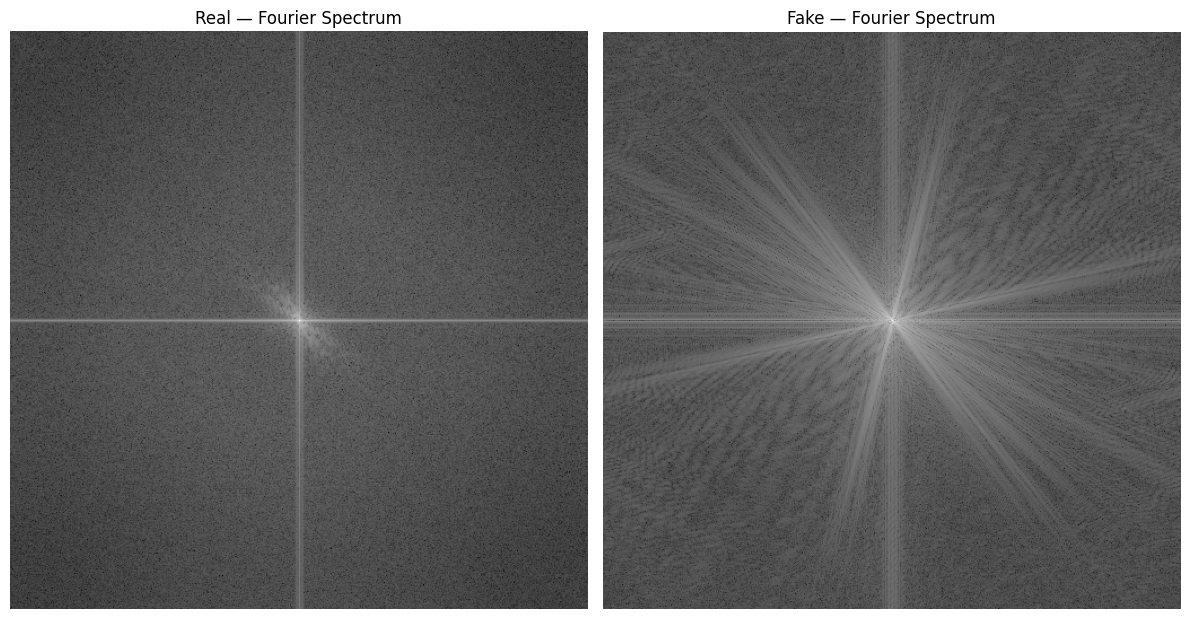

In [58]:
import numpy as np
from src.spectral import compute_fft , compute_power_spectrum
from pathlib import Path


real_fft = compute_fft(real_image)
fake_fft = compute_fft(fake_image)
print("real_fft properties:", real_fft.shape, real_fft.dtype, real_fft.min(), real_fft.max())
print("fake_fft properties:", fake_fft.shape, fake_fft.dtype, fake_fft.min(), fake_fft.max())

# Center low frequencies
real_shifted = np.fft.fftshift(real_fft)
fake_shifted = np.fft.fftshift(fake_fft)

# Compute log-magnitude spectra
real_spectrum = np.log1p(np.abs(real_shifted))
fake_spectrum = np.log1p(np.abs(fake_shifted))

# Visualization
fig, axes = plt.subplots(1, 2, figsize=(12, 12))

vmin = min(real_spectrum.min(), fake_spectrum.min())
vmax = max(real_spectrum.max(), fake_spectrum.max())

axes[0].imshow(real_spectrum, cmap="gray", vmin=vmin, vmax=vmax)
axes[0].set_title("Real — Fourier Spectrum")

axes[1].imshow(fake_spectrum, cmap="gray", vmin=vmin, vmax=vmax)
axes[1].set_title("Fake — Fourier Spectrum")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

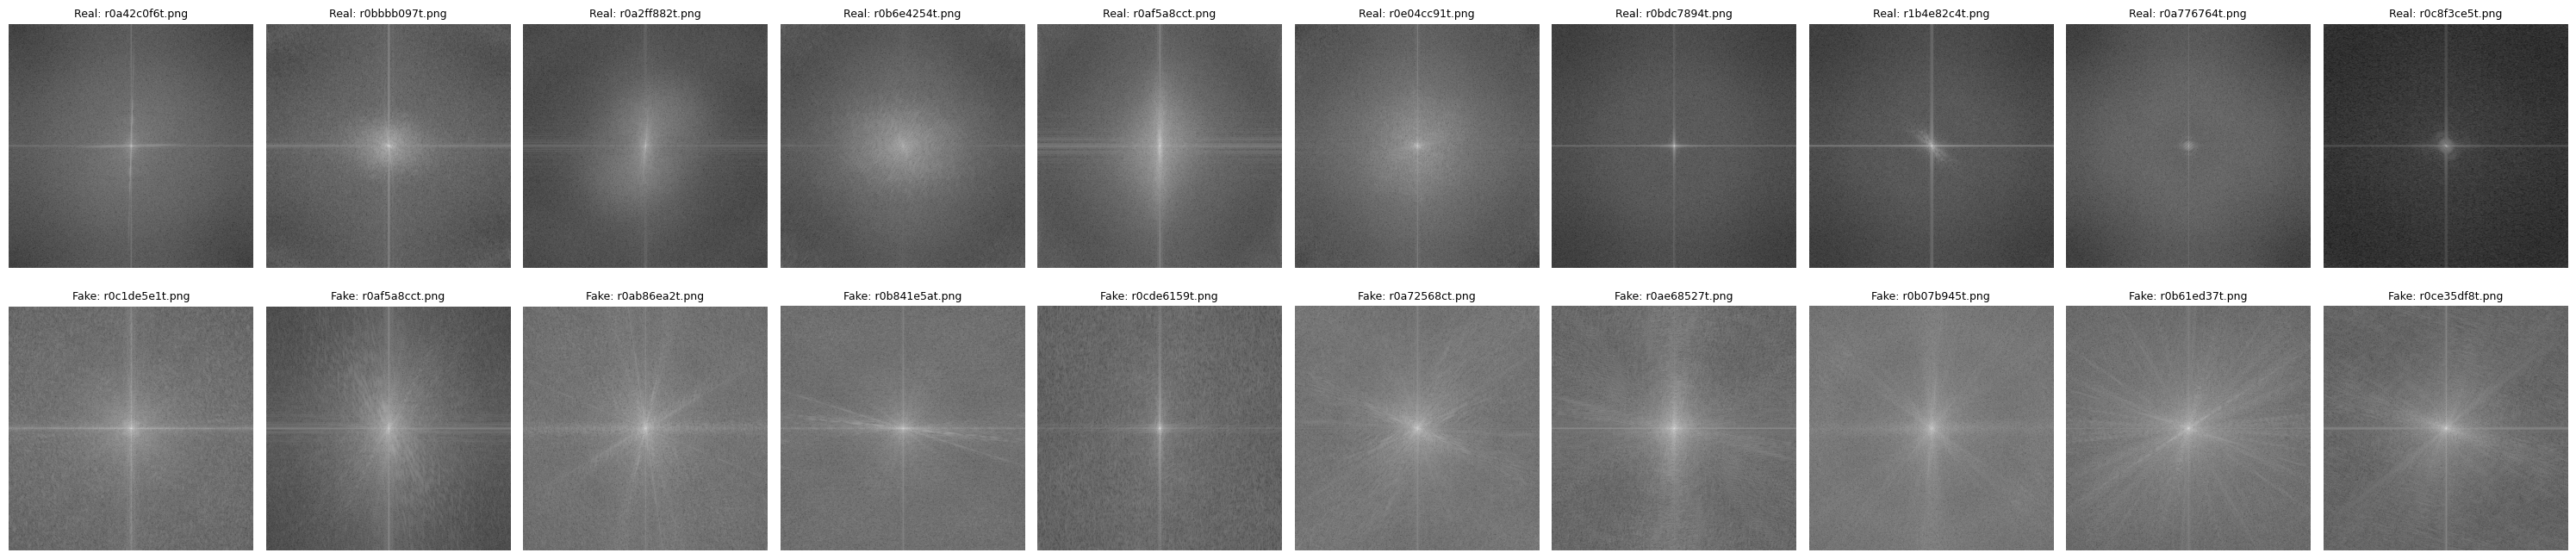

In [ ]:

from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from src.spectral import compute_fft , compute_power_spectrum

# Dataset location
root = Path.cwd().parent #if Path.cwd().name == "notebooks" else Path.cwd()
data_dir = root / "data"

rng = np.random.default_rng(seed=42)

def get_spectra(folder, n):
    all_paths = sorted(p for p in folder.iterdir())
    paths = rng.choice(all_paths, size=n, replace=False)

    spectra = []

    for path in paths:
        image = load_image(path)
        cropped = center_crop(image, 512)

        fft = compute_fft(cropped)
        spectrum = np.log1p(np.abs(np.fft.fftshift(fft)))

        spectra.append(spectrum)

    return spectra, paths


n = 10  # Number of images per class
real_spectra, real_paths = get_spectra(data_dir / "real", n)
fake_spectra, fake_paths = get_spectra(data_dir / "fake", n)

# Same intensity scale for every spectrum
all_spectra = real_spectra + fake_spectra
vmin = min(s.min() for s in all_spectra)
vmax = max(s.max() for s in all_spectra)

fig, axes = plt.subplots(2, n, figsize=(3*n, 7), squeeze=False)

for row, (spectra, paths, label) in enumerate([
    (real_spectra, real_paths, "Real"),
    (fake_spectra, fake_paths, "Fake")
]):
    for j, (spectrum, path) in enumerate(zip(spectra, paths)):
        axes[row, j].imshow(
            spectrum, cmap="gray", vmin=vmin, vmax=vmax
        )
        axes[row, j].set_title(f"{label}: {path.name}", fontsize=9)
        axes[row, j].axis("off")

plt.tight_layout()
plt.show()


In [66]:
##Averaging the power spectra of all images in the dataset
from src.spectral import compute_fft , compute_power_spectrum
def average_power_spectrum(folder):
    all_paths = sorted(p for p in folder.iterdir())

    total_power=np.zeros((512, 512), dtype=np.float64)
    for path in all_paths:
        image=load_image(path)
        image=center_crop(image, 512)
        spectrum = compute_power_spectrum(image)
        total_power += spectrum
    mean_power = total_power / len(all_paths)

    return np.fft.fftshift(mean_power)




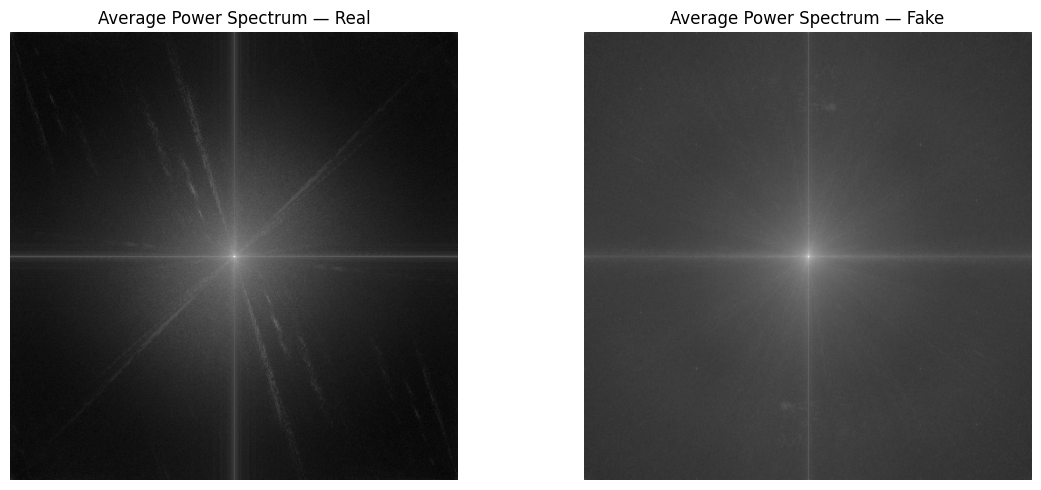

In [68]:
real_mean = average_power_spectrum(data_dir / "real")
fake_mean = average_power_spectrum(data_dir / "fake")

# Logarithmic scaling for visualization
real_log = np.log1p(real_mean)
fake_log = np.log1p(fake_mean)

# Common intensity range
vmin = min(real_log.min(), fake_log.min())
vmax = max(real_log.max(), fake_log.max())

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

axes[0].imshow(real_log, cmap="gray", vmin=vmin, vmax=vmax)
axes[0].set_title("Average Power Spectrum — Real")

axes[1].imshow(fake_log, cmap="gray", vmin=vmin, vmax=vmax)
axes[1].set_title("Average Power Spectrum — Fake")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()